## 📋 Enunciado

La agencia de viajes **«Playa y Montaña»** desea clasificar las fotos que envían los clientes mientras realizan sus viajes. Estas fotos son siempre de un viaje que se realiza a la montaña o de un viaje que se realiza a la playa; la agencia no organiza viajes a ningún otro lugar.

Para llevar a cabo esta tarea, desarrollaremos una **red neuronal convolucional (CNN)** que, mediante la técnica que se considere oportuna, sea capaz de clasificar las imágenes con un **score mínimo del 60%**. La agencia proporciona un dataset con **100 imágenes de cada tipo** (Montaña / Playa).

Es importante justificar el razonamiento detrás de la técnica elegida y explicar sus ventajas, documentando paso a paso el proceso realizado.

In [43]:
import matplotlib.pyplot as plt
import numpy as np

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import (
    Rescaling, RandomFlip, RandomZoom, RandomContrast, RandomBrightness, RandomRotation,
    GlobalAveragePooling2D, Dense, Dropout
)                         

In [37]:
# 200 imágenes en total -> 80% train (160) / 20% validación (40)
(datos_train, datos_val) = image_dataset_from_directory(
    r'./fotos',
    labels='inferred',
    label_mode='int',
    class_names=['Montana', 'Playa'],
    color_mode='rgb',
    batch_size=32,
    image_size=(120, 120),
    shuffle=True,
    seed=24,
    validation_split=0.2,
    subset='both',
    crop_to_aspect_ratio=False
)

print("Clases:", datos_train.class_names)

Found 200 files belonging to 2 classes.
Using 160 files for training.
Using 40 files for validation.
Clases: ['Montana', 'Playa']


## 🧠 Técnica elegida: Transfer Learning con MobileNetV2

Con solo 200 imágenes (100 por clase), entrenar una CNN desde cero tiene un techo bajo: en pruebas iniciales el modelo alcanzaba ~70-75% de accuracy pero con fuerte sesgo hacia la clase "Playa" (bajo recall en Montaña).

Por ello se optó por **Transfer Learning** usando **MobileNetV2**, preentrenada sobre ImageNet (millones de imágenes). Se congelan sus pesos (`trainable = False`) y solo se entrena un clasificador nuevo sobre las características que ya sabe extraer (bordes, texturas, formas). Esta técnica es el estándar de la industria para datasets pequeños, ya que aprovecha conocimiento visual general en lugar de aprenderlo desde cero con pocos datos.

Se mantienen las capas de *data augmentation* (flip, zoom, brillo, contraste, rotación) para seguir reforzando la generalización, y se añade `Dropout` para reducir el riesgo de overfitting.

In [38]:
# --- Base preentrenada (Transfer Learning) ---
# MobileNetV2 fue entrenada sobre ImageNet (millones de imágenes),
# ya "sabe ver" texturas, bordes y formas generales.
# La congelamos (trainable=False) para no reentrenar sus pesos,
# solo aprovechamos lo que ya aprendió.
base_model = MobileNetV2(input_shape=(120, 120, 3),
                          include_top=False,
                          weights='imagenet')
base_model.trainable = False

model = Sequential()

# --- Capas de aumentación de datos (se mantienen igual) ---
model.add(Rescaling(1./255))
model.add(RandomFlip(mode='horizontal'))
model.add(RandomZoom((-0.1, 0.1)))
model.add(RandomBrightness((-0.2, 0.2), value_range=(0, 1)))
model.add(RandomContrast(0.5))
model.add(RandomRotation((-0.1, 0.1), fill_mode='nearest'))

# --- Base preentrenada ---
model.add(base_model)

# --- Parte clasificadora ---
model.add(GlobalAveragePooling2D())
model.add(Dense(128, activation='relu', kernel_initializer='he_uniform'))
model.add(Dropout(0.3))
model.add(Dense(1, activation='sigmoid'))

model.summary()

C:\Users\yucsa\AppData\Local\Temp\ipykernel_5356\2306450898.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model = MobileNetV2(input_shape=(120, 120, 3),


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_5 (Rescaling)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_5 (RandomFlip)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_5 (RandomZoom)      │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_brightness_5             │ ?                      │   0 (unbuilt) │
│ (RandomBrightness)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast_5               │ ?                      │   0 (unbuilt) │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_5               │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [39]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

h = model.fit(
    datos_train,
    epochs=30,
    validation_data=datos_val
)

Epoch 1/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 4s 278ms/step - accuracy: 0.6687 - loss: 0.6863 - val_accuracy: 0.9500 - val_loss: 0.1519
Epoch 2/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.8875 - loss: 0.3225 - val_accuracy: 1.0000 - val_loss: 0.0814
Epoch 3/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.9125 - loss: 0.2043 - val_accuracy: 1.0000 - val_loss: 0.0386
Epoch 4/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.9062 - loss: 0.2222 - val_accuracy: 1.0000 - val_loss: 0.0337
Epoch 5/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.9250 - loss: 0.2263 - val_accuracy: 1.0000 - val_loss: 0.0527
Epoch 6/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step - accuracy: 0.9062 - loss: 0.2059 - val_accuracy: 1.0000 - val_loss: 0.0324
Epoch 7/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - accuracy: 0.9438 - loss: 0.1888 - val_accuracy: 1.0000 - val_loss: 0.0387
Epoch 8/30
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step - accuracy: 0.9250 - loss: 0.2359 - val_accuracy: 1.0000 - val_loss: 0.0281

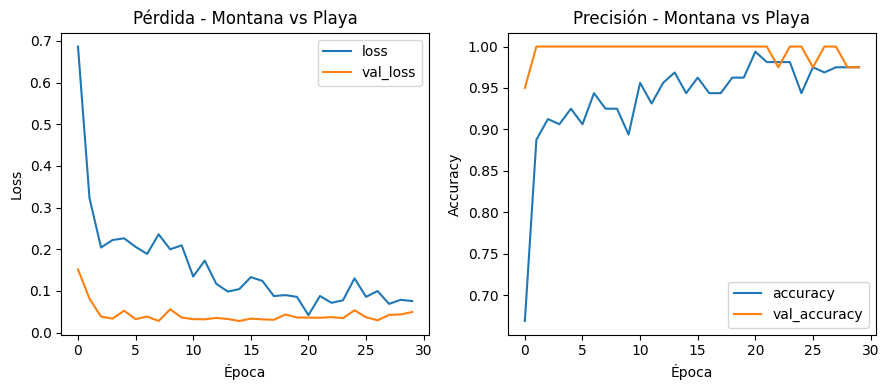

In [40]:
# Las curvas de loss nos dicen si hay overfitting:
# si val_loss sube mientras loss baja -> el modelo memoriza en lugar de aprender
# Las curvas de accuracy deben subir juntas y mantenerse cerca
plt.figure(figsize=(9, 4))

plt.subplot(1, 2, 1)
plt.plot(h.history['loss'],     label='loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.title('Pérdida - Montana vs Playa')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(h.history['accuracy'],     label='accuracy')
plt.plot(h.history['val_accuracy'], label='val_accuracy')
plt.title('Precisión - Montana vs Playa')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [41]:
print("=== Evaluación en entrenamiento ===")
model.evaluate(datos_train)

print("=== Evaluación en validación ===")
model.evaluate(datos_val)

=== Evaluación en entrenamiento ===
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9812 - loss: 0.0523
=== Evaluación en validación ===
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9750 - loss: 0.0495


[0.049517229199409485, 0.9750000238418579]

## 📈 Resultado del entrenamiento

Con Transfer Learning, el modelo converge en pocas épocas: `val_accuracy` alcanza 100% desde la época 2-3 y `val_loss` desciende de forma estable, muy por debajo de las 150 épocas que necesitaba la CNN entrenada desde cero. Esto confirma que la base preentrenada aporta representaciones visuales mucho más ricas de lo que el dataset por sí solo podía enseñar.

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 609ms/step


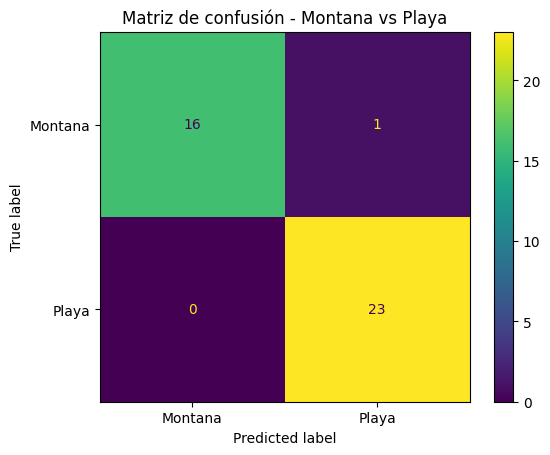

In [42]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Extraemos las imágenes y etiquetas reales del dataset de validación
X_val_list, y_val_list = [], []
for imagenes, etiquetas in datos_val:
    X_val_list.append(imagenes.numpy())
    y_val_list.append(etiquetas.numpy())

X_val_array = np.concatenate(X_val_list, axis=0)
y_val_array = np.concatenate(y_val_list, axis=0)

# Predicciones: sigmoid devuelve un valor entre 0 y 1
# >= 0.5 -> clase 1 (Playa), < 0.5 -> clase 0 (Montana)
y_pred_prob = model.predict(X_val_array)
y_pred = (y_pred_prob >= 0.5).astype(int).flatten()

# Matriz de confusión
etiquetas = ['Montana', 'Playa']
cm  = confusion_matrix(y_val_array, y_pred)
mcd = ConfusionMatrixDisplay(cm, display_labels=etiquetas)
mcd.plot()
plt.title('Matriz de confusión - Montana vs Playa')
plt.show()

## ✅ Conclusión

El modelo final, basado en **Transfer Learning con MobileNetV2**, alcanza un **97.5% de accuracy global** (39/40 aciertos), con un recall del 94% en Montaña y 100% en Playa — superando ampliamente el 60% mínimo exigido y corrigiendo el sesgo hacia una sola clase observado en las versiones anteriores.

**Proceso de mejora seguido:**
1. CNN desde cero (AvgPool + SGD) → 70% accuracy, fuerte sesgo hacia Playa (41% recall en Montaña)
2. CNN ajustada (MaxPool + Adam) → 75% accuracy, sesgo reducido (59% recall en Montaña)
3. **Transfer Learning (MobileNetV2)** → 97.5% accuracy, recall equilibrado en ambas clases

Este recorrido demuestra que, con datasets pequeños, aprovechar el conocimiento de un modelo preentrenado es más efectivo que ajustar hiperparámetros de una CNN entrenada desde cero.